In [1]:
# ==================================================================================
# Carrera de Ingeniería de Sistemas
# Universidad Franz Tamayo
# ----------------------------------------------------------------------------------
#                       Asignatura: MINERIA DE DATOS
# ----------------------------------------------------------------------------------
#         Enrique Alejandro Laurel Cossio, Septiembre 2026
# ==================================================================================
#                      TEMA: REGRESIÓN LOGÍSTICA
# ==================================================================================

# 1. LIBRERIAS Y FUNCIONES

In [1]:
# Cargamos Librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [2]:
import warnings

HOLA regresion logistica

# 2. PARAMETROS

# 3. Datos

In [12]:
pd.set_option('display.max_columns', None)

In [13]:
# cargamos datos
ifood_df = pd.read_excel('base_de_datos_medicina_complicaciones_modificada.xlsx')

print(ifood_df.shape) #
ifood_df.head(2)

(10000, 41)


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...


In [14]:
ifood_df

,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,Maestria,Nivel 2 - Pobreza,Oruro,Oruro,"Zona Sur, Calle 33, Av. 196",75137722,Instituto de Seguros Sociales (CNS),Unidad de Salud,05/03/2024,Hernia Discal; Vacunacion; Infecciones Urinarias,Orina Frecuente; Erupcion Cutanea; Ganancia de...,A+,134.7,115.3,101.3,100/104,58,37.4,212,219,320,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...
3,BNS-2024-000004,4337174 SC,Marcelo,Ramirez,Palacios,M,27/07/1935,91,Divorciado/a,Desempleado/a,Maestria,Nivel 3 - Vulnerable,Santa Cruz,Santa Cruz,"Zona Sur, Calle 29, Av. 133",77273233,Seguro Básico de Salud (SBS),Hospital Docente,10/04/2024,Parto Normal; Apendicitis,Fiebre; Dolor Toracico; Ojos Llorosos; Tos; Mareo,B+,46.4,187.8,13.2,90/60,112,39.6,254,236,114,9.3,2.53,Pendiente,Resonancia Magnetica,0,Control de Glucosa,11,Estable,Fallo Multiorgánico,Registro generado automaticamente por el Banco...
4,BNS-2023-000005,1352896 PD,Hugo,Sanchez,Rojas,M,30/12/1965,60,Casado/a,Comerciante,Educacion Inicial,Nivel 4 - Medio Bajo,Beni,Trinidad,"Zona Centro, Calle 4, Av. 104",74860684,Instituto de Seguros Sociales (CNS),Hospital Pediatrico,20/04/2023,Hipertension Arterial; Gastritis,Ganancia de Peso,O+,47.8,123.8,31.2,165/112,77,38.2,245,246,345,12.7,3.99,Positivo,Fisioterapia,0,Control Prenatal,6,Mejorando,Embolia,Registro generado automaticamente por el Banco...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,BNS-2021-009996,4669623 TJ,Hugo,Coaqui,Vargas,M,06/11/1943,82,Casado/a,Am(a) de casa,Maestria,Nivel 7 - Alto,Pando,Cobija,"Zona Este, Calle 26, Av. 145",79160615,Instituto de Seguros Sociales (CNS),Hospital Docente,29/12/2021,Gota,Orina Frecuente,B+,109.2,180.7,33.4,88/52,96,38.4,182,129,54,12.7,1.49,Indeterminado,Terapia Intensiva,30,Electrocardiograma,12,Mejorando,Hemorragia,Registro generado automaticamente por el Banco...
9996,BNS-2024-009997,9769005 PD,Edwin,Huanca,Chambi,M,25/08/2016,10,Soltero/a,Estudiante,Primaria Incompleta,Nivel 5 - Medio,Tarija,Tarija,"Zona Este, Calle 20, Av. 55",75686894,Servicio de Atencion Medica (SAM),Hospital Pediatrico,01/04/2024,Hernia Discal,Picazon; Estreñimiento; Perdida del Apetito,A+,49.9,111.8,39.9,154/75,85,39.

# 4. PROCESO

## 4.1. ENTENDIMIENTO Y PREPARACIÓN DE DATOS

In [15]:
ifood_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NRO_REGISTRO           10000 non-null  str    
 1   CI_PACIENTE            10000 non-null  str    
 2   NOMBRE                 10000 non-null  str    
 3   APELLIDO1              10000 non-null  str    
 4   APELLIDO2              10000 non-null  str    
 5   SEXO                   10000 non-null  str    
 6   FECHA_NACIMIENTO       10000 non-null  str    
 7   EDAD                   10000 non-null  int64  
 8   ESTADO_CIVIL           10000 non-null  str    
 9   OCUPACION              10000 non-null  str    
 10  NIVEL_EDUCATIVO        10000 non-null  str    
 11  NIVEL_SOCIOECONOMICO   10000 non-null  str    
 12  DEPARTAMENTO           10000 non-null  str    
 13  CAPITAL_DEPTO          10000 non-null  str    
 14  DIRECCION              10000 non-null  str    
 15  TELEFONO      

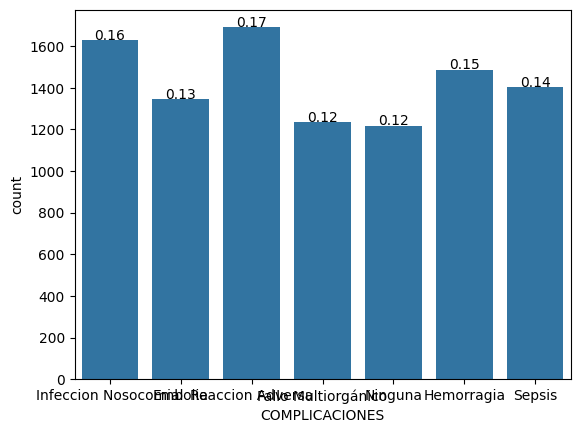

In [16]:
# Distribución de los tipos de complicaciones médicas
ax = sns.countplot(x='COMPLICACIONES', data=ifood_df)
total = float(len(ifood_df))
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}'.format(height/total),
            ha="center")
plt.show()

### Métrica principal del proyecto

**KPI de negocio:** Prevalencia de Complicaciones.

Prevalencia = (Pacientes con alguna complicación / Total de pacientes) × 100

Baseline actual: **87.82 %**

Meta del negocio: reducir la prevalencia a un máximo de **75 %**.

**Métrica técnica principal del modelo:** Recall (Sensibilidad).

El modelo deberá alcanzar un **Recall ≥ 0.70**, con el objetivo de identificar correctamente al menos al 70 % de los pacientes que realmente presentan una complicación.

In [17]:
# una copia a los datos
df = ifood_df.copy()

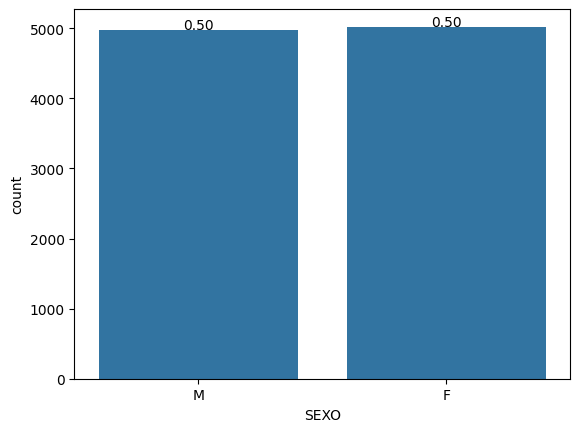

In [18]:
# grafico de barras de la variable "Education" en el data frame df
ax = sns.countplot(x='SEXO', data=df)
total = float(len(df))
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}'.format(height/total),
            ha="center")
plt.show()

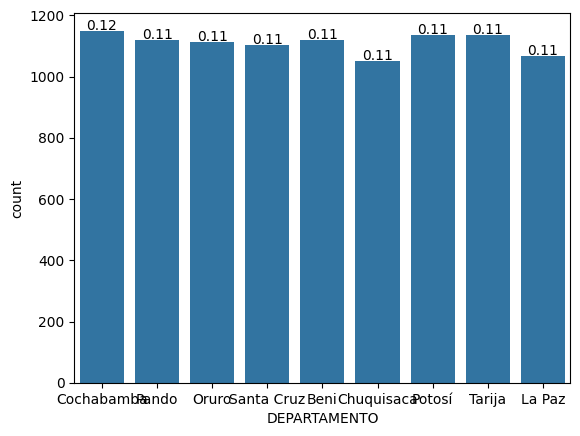

In [19]:
ax = sns.countplot(x='DEPARTAMENTO', data=df)
total = float(len(df))
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}'.format(height/total),
            ha="center")
plt.show()

In [20]:
df.columns

Index(['NRO_REGISTRO', 'CI_PACIENTE', 'NOMBRE', 'APELLIDO1', 'APELLIDO2',
       'SEXO', 'FECHA_NACIMIENTO', 'EDAD', 'ESTADO_CIVIL', 'OCUPACION',
       'NIVEL_EDUCATIVO', 'NIVEL_SOCIOECONOMICO', 'DEPARTAMENTO',
       'CAPITAL_DEPTO', 'DIRECCION', 'TELEFONO', 'ASEGURAMIENTO',
       'ESTABLECIMIENTO_SALUD', 'FECHA_REGISTRO', 'ENFERMEDADES', 'SINTOMAS',
       'GRUPO_SANGUINEO', 'PESO_KG', 'ESTATURA_CM', 'IMC', 'PRESION_ARTERIAL',
       'FRECUENCIA_CARDIACA', 'TEMPERATURA_C', 'GLUCEMIA', 'COLESTEROL_TOTAL',
       'TRIGLICERIDOS', 'HEMOGLOBINA', 'CREATININA', 'RESULTADO_LABORATORIO',
       'TRATAMIENTO', 'DIAS_HOSPITALIZACION', 'MEDIDA_PREVENCION',
       'NUMERO_CONTROLES', 'ESTADO_PACIENTE', 'COMPLICACIONES',
       'OBSERVACIONES'],
      dtype='str')

In [21]:
df.head(2)

,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...


In [22]:
df['DEPARTAMENTO'].value_counts()

DEPARTAMENTO
Cochabamba    1150
Potosí        1135
Tarija        1135
Pando         1121
Beni          1120
Oruro         1114
Santa Cruz    1104
La Paz        1069
Chuquisaca    1052
Name: count, dtype: int64

In [23]:
df.describe()

,EDAD,TELEFONO,PESO_KG,ESTATURA_CM,IMC,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,DIAS_HOSPITALIZACION,NUMERO_CONTROLES
count,10000.000000,1.000000e+04,10000.000000,10000.000000,9918.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,46.936200,7.548072e+07,91.570390,145.582480,51.425711,84.857200,38.012810,180.301300,199.838900,224.719900,13.023410,2.649961,1.794100,6.001700
std,27.547588,2.594845e+06,33.485332,34.600805,39.324128,20.294507,1.449198,69.114544,58.439698,101.269021,2.896742,1.354487,5.810911,3.765251
min,0.000000,7.100100e+07,2.600000,45.300000,0.700000,50.000000,35.500000,60.000000,100.000000,50.000000,8.000000,0.300000,0.000000,0.000000
25%,23.000000,7.324466e+07,64.475000,120.800000,28.000000,67.000000,36.800000,121.000000,149.000000,136.000000,10.500000,1.500000,0.000000,3.000000
50%,47.000000,7.541180e+07,92.000000,147.400000,41.000000,85.000000,38.000000,181.000000,200.000000,225.000000,13.100000,2.630000,0.000000,6.000000
75%,71.000000,7.774810e+07,119.200000,174.125000,62.775000,102.250000,39.300000,239.000000,251.000000,312.000000,15.600000,3.820000,0.000000,9.000000
max,95.000000,7.999966e+07,150.000000,200.000000,418.000000,120.000000,40.500000,300.000000,300.000000,400.000000,18.000000,5.000000,30.000000,12.000000


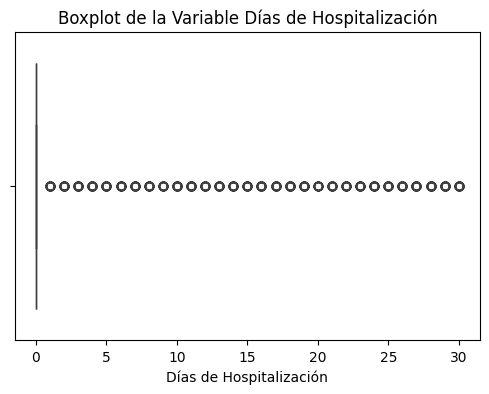

In [24]:
# Boxplot de DIAS_HOSPITALIZACION
plt.figure(figsize=(6,4))
sns.boxplot(x=df['DIAS_HOSPITALIZACION'])
plt.title('Boxplot de la Variable Días de Hospitalización')
plt.xlabel('Días de Hospitalización')
plt.show()

In [25]:
# Convertimos variables categoricas a variables dummy
df = pd.get_dummies(df, columns=['SEXO', 'DEPARTAMENTO'], drop_first=True)
#df['SEXO'] = df['SEXO']
print(df.shape)
df.head(2)

(10000, 48)


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES,SEXO_M,DEPARTAMENTO_Chuquisaca,DEPARTAMENTO_Cochabamba,DEPARTAMENTO_La Paz,DEPARTAMENTO_Oruro,DEPARTAMENTO_Pando,DEPARTAMENTO_Potosí,DEPARTAMENTO_Santa Cruz,DEPARTAMENTO_Tarija
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...,True,False,True,False,False,False,False,False,False
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...,False,False,False,False,False,True,False,False,False


In [26]:
# Convertimos a entero todos los campos que empiezan con 'SEXO' o 'DEPARTAMENTO'
for col in df.columns:
    if col.startswith('SEXO') or col.startswith('DEPARTAMENTO'):
        if df[col].dtype == bool:
            df[col] = df[col].astype(int)

df[[c for c in df.columns if c.startswith('SEXO') or c.startswith('DEPARTAMENTO')]].head(2)

print(df.shape)
df.head(2)

(10000, 48)


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES,SEXO_M,DEPARTAMENTO_Chuquisaca,DEPARTAMENTO_Cochabamba,DEPARTAMENTO_La Paz,DEPARTAMENTO_Oruro,DEPARTAMENTO_Pando,DEPARTAMENTO_Potosí,DEPARTAMENTO_Santa Cruz,DEPARTAMENTO_Tarija
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...,1,0,1,0,0,0,0,0,0
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...,0,0,0,0,0,1,0,0,0


## 4.2. Modelo

In [27]:
df.columns

Index(['NRO_REGISTRO', 'CI_PACIENTE', 'NOMBRE', 'APELLIDO1', 'APELLIDO2',
       'FECHA_NACIMIENTO', 'EDAD', 'ESTADO_CIVIL', 'OCUPACION',
       'NIVEL_EDUCATIVO', 'NIVEL_SOCIOECONOMICO', 'CAPITAL_DEPTO', 'DIRECCION',
       'TELEFONO', 'ASEGURAMIENTO', 'ESTABLECIMIENTO_SALUD', 'FECHA_REGISTRO',
       'ENFERMEDADES', 'SINTOMAS', 'GRUPO_SANGUINEO', 'PESO_KG', 'ESTATURA_CM',
       'IMC', 'PRESION_ARTERIAL', 'FRECUENCIA_CARDIACA', 'TEMPERATURA_C',
       'GLUCEMIA', 'COLESTEROL_TOTAL', 'TRIGLICERIDOS', 'HEMOGLOBINA',
       'CREATININA', 'RESULTADO_LABORATORIO', 'TRATAMIENTO',
       'DIAS_HOSPITALIZACION', 'MEDIDA_PREVENCION', 'NUMERO_CONTROLES',
       'ESTADO_PACIENTE', 'COMPLICACIONES', 'OBSERVACIONES', 'SEXO_M',
       'DEPARTAMENTO_Chuquisaca', 'DEPARTAMENTO_Cochabamba',
       'DEPARTAMENTO_La Paz', 'DEPARTAMENTO_Oruro', 'DEPARTAMENTO_Pando',
       'DEPARTAMENTO_Potosí', 'DEPARTAMENTO_Santa Cruz',
       'DEPARTAMENTO_Tarija'],
      dtype='str')

In [28]:
df['COMPLICACIONES'].unique()

<StringArray>
['Infeccion Nosocomial',              'Embolia',     'Reaccion Adversa',
  'Fallo Multiorgánico',              'Ninguna',           'Hemorragia',
               'Sepsis']
Length: 7, dtype: str

In [39]:
# ============================================================
# VARIABLE OBJETIVO
# ============================================================

# 1 = paciente con alguna complicación
# 0 = paciente sin complicación ("Ninguna")
y = (df['COMPLICACIONES'] != 'Ninguna').astype(int)


# ============================================================
# VARIABLES PREDICTORAS
# ============================================================

# Variables clínicas y demográficas disponibles al ingreso.
# Se utilizan variables numéricas y las variables dummy
# generadas para SEXO y DEPARTAMENTO.

columnas_modelo = [
    'EDAD',
    'GLUCEMIA'
]

# Agregamos SEXO y DEPARTAMENTO ya transformados a variables dummy
columnas_modelo += [
    col for col in df.columns
    if col.startswith('SEXO_') or col.startswith('DEPARTAMENTO_')
]

X = df[columnas_modelo].copy()


# ============================================================
# VERIFICACIÓN
# ============================================================

print("Variables utilizadas en el modelo:")
print(X.columns.tolist())

print("\nTipos de datos:")
print(X.dtypes)

print("\nValores faltantes:")
print(X.isnull().sum())

print("\nDistribución del target:")
print(y.value_counts())

print("\nProporción del target:")
print(y.value_counts(normalize=True))

Variables utilizadas en el modelo:
['EDAD', 'GLUCEMIA', 'SEXO_M', 'DEPARTAMENTO_Chuquisaca', 'DEPARTAMENTO_Cochabamba', 'DEPARTAMENTO_La Paz', 'DEPARTAMENTO_Oruro', 'DEPARTAMENTO_Pando', 'DEPARTAMENTO_Potosí', 'DEPARTAMENTO_Santa Cruz', 'DEPARTAMENTO_Tarija']

Tipos de datos:
EDAD                       int64
GLUCEMIA                   int64
SEXO_M                     int64
DEPARTAMENTO_Chuquisaca    int64
DEPARTAMENTO_Cochabamba    int64
DEPARTAMENTO_La Paz        int64
DEPARTAMENTO_Oruro         int64
DEPARTAMENTO_Pando         int64
DEPARTAMENTO_Potosí        int64
DEPARTAMENTO_Santa Cruz    int64
DEPARTAMENTO_Tarija        int64
dtype: object

Valores faltantes:
EDAD                       0
GLUCEMIA                   0
SEXO_M                     0
DEPARTAMENTO_Chuquisaca    0
DEPARTAMENTO_Cochabamba    0
DEPARTAMENTO_La Paz        0
DEPARTAMENTO_Oruro         0
DEPARTAMENTO_Pando         0
DEPARTAMENTO_Potosí        0
DEPARTAMENTO_Santa Cruz    0
DEPARTAMENTO_Tarija        0
dtype: 

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=777,
    stratify=y
)

In [41]:
# tamaño de datos de entrenamiento
print('tamaño train', X_train.shape)
print('tamaño de test', X_test.shape)

tamaño train (8000, 11)
tamaño de test (2000, 11)


In [42]:
# ============================================================
# PREPARACIÓN DE DATOS PARA REGRESIÓN LOGÍSTICA
# ============================================================

# Convertimos todas las variables predictoras a formato numérico
X_train_logit = X_train.astype(float)
X_test_logit = X_test.astype(float)

# Target binario
y_train_logit = y_train.astype(int)
y_test_logit = y_test.astype(int)

# Agregamos constante (intercepto)
X_train_const = sm.add_constant(
    X_train_logit,
    has_constant='add'
)

X_test_const = sm.add_constant(
    X_test_logit,
    has_constant='add'
)

print("Tipos de datos:")
print(X_train_const.dtypes)

print("\nValores faltantes:")
print(X_train_const.isnull().sum())

print("\nTamaño TRAIN:", X_train_const.shape)
print("Tamaño TEST:", X_test_const.shape)

Tipos de datos:
const                      float64
EDAD                       float64
GLUCEMIA                   float64
SEXO_M                     float64
DEPARTAMENTO_Chuquisaca    float64
DEPARTAMENTO_Cochabamba    float64
DEPARTAMENTO_La Paz        float64
DEPARTAMENTO_Oruro         float64
DEPARTAMENTO_Pando         float64
DEPARTAMENTO_Potosí        float64
DEPARTAMENTO_Santa Cruz    float64
DEPARTAMENTO_Tarija        float64
dtype: object

Valores faltantes:
const                      0
EDAD                       0
GLUCEMIA                   0
SEXO_M                     0
DEPARTAMENTO_Chuquisaca    0
DEPARTAMENTO_Cochabamba    0
DEPARTAMENTO_La Paz        0
DEPARTAMENTO_Oruro         0
DEPARTAMENTO_Pando         0
DEPARTAMENTO_Potosí        0
DEPARTAMENTO_Santa Cruz    0
DEPARTAMENTO_Tarija        0
dtype: int64

Tamaño TRAIN: (8000, 12)
Tamaño TEST: (2000, 12)


In [43]:
# ============================================================
# MODELO DE REGRESIÓN LOGÍSTICA
# ============================================================

modelo_logit = sm.Logit(
    y_train_logit,
    X_train_const
).fit()

print(modelo_logit.summary())

Optimization terminated successfully.
         Current function value: 0.369643
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:         COMPLICACIONES   No. Observations:                 8000
Model:                          Logit   Df Residuals:                     7988
Method:                           MLE   Df Model:                           11
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                0.002038
Time:                        14:40:49   Log-Likelihood:                -2957.1
converged:                       True   LL-Null:                       -2963.2
Covariance Type:            nonrobust   LLR p-value:                    0.3580
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       1.8674      0.152     12.314      0.000       1.570   

# 4.3. Evaluación

### 4.3.1. Resultados del Modelo

In [44]:
# Muestra un resumen del modelo
print(modelo_logit.summary())

                           Logit Regression Results                           
Dep. Variable:         COMPLICACIONES   No. Observations:                 8000
Model:                          Logit   Df Residuals:                     7988
Method:                           MLE   Df Model:                           11
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                0.002038
Time:                        14:41:53   Log-Likelihood:                -2957.1
converged:                       True   LL-Null:                       -2963.2
Covariance Type:            nonrobust   LLR p-value:                    0.3580
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       1.8674      0.152     12.314      0.000       1.570       2.165
EDAD                        0.0019      0.001      1.556      0.120      -0.001       0.004


In [48]:
# Evaluación manual de la logit (z) para un paciente de 60 años y 5 días hospitalizado
0.0355 * 60 + 0.0295 * 5

2.2775

In [50]:
# Predicción de probabilidades en los datos de entrenamiento
y_prob_train = modelo_logit.predict(X_train_const)

y_prob_train.head(20)

8949    0.884123
8527    0.881848
9126    0.885008
5947    0.871168
6750    0.878296
9139    0.863643
8933    0.861001
2216    0.887054
740     0.867292
3015    0.886482
9138    0.869996
9897    0.891271
9950    0.885705
2354    0.902133
7137    0.877723
4275    0.880302
239     0.858844
8366    0.878326
8423    0.874667
6879    0.893779
dtype: float64

In [54]:
# Tamaño del conjunto de entrenamiento utilizado por el modelo
print("Tamaño de X_train:", X_train_logit.shape)
print("Tamaño de X_test:", X_test_logit.shape)

Tamaño de X_train: (8000, 11)
Tamaño de X_test: (2000, 11)


In [56]:
# ============================================================
# PREDICCIÓN EN EL CONJUNTO DE ENTRENAMIENTO
# ============================================================

# Probabilidades predichas por el modelo
y_prob_train = modelo_logit.predict(X_train_const)

# Convertimos las probabilidades en clases
# 0 = Sin complicación
# 1 = Con complicación
y_pred_train_clase = (y_prob_train >= 0.50).astype(int)

print("Primeras probabilidades:")
print(y_prob_train.head())

print("\nPrimeras clases predichas:")
print(y_pred_train_clase.head())

Primeras probabilidades:
8949    0.884123
8527    0.881848
9126    0.885008
5947    0.871168
6750    0.878296
dtype: float64

Primeras clases predichas:
8949    1
8527    1
9126    1
5947    1
6750    1
dtype: int64


In [57]:
# ============================================================
# EVALUACIÓN DEL MODELO EN ENTRENAMIENTO
# ============================================================

# Accuracy: proporción total de predicciones correctas
exactitud_train = accuracy_score(
    y_train_logit,
    y_pred_train_clase
)

# Recall: proporción de pacientes con complicación
# que fueron correctamente identificados
recall_train = recall_score(
    y_train_logit,
    y_pred_train_clase
)

print("Accuracy del modelo en TRAIN:", round(exactitud_train, 4))
print("Recall del modelo en TRAIN:", round(recall_train, 4))

Accuracy del modelo en TRAIN: 0.8782
Recall del modelo en TRAIN: 1.0


### Principales métricas de clasificación desde la matriz de confusión

La **matriz de confusión** resume los resultados de un modelo de clasificación comparando las predicciones con los valores reales. Sus componentes son:

- **TP (True Positives)**: casos positivos correctamente clasificados.  
- **TN (True Negatives)**: casos negativos correctamente clasificados.  
- **FP (False Positives)**: casos negativos mal clasificados como positivos.  
- **FN (False Negatives)**: casos positivos mal clasificados como negativos.  

A partir de estos valores se derivan las métricas:

- **Exactitud (Accuracy)**: proporción de predicciones correctas.  
  \[
  $$\text{Accuracy} = {TP + TN}/{TP + TN + FP + FN}$$
  \]

- **Precisión (Precision)**: de los casos predichos como positivos, cuántos realmente lo son.  
  \[
  \text{Precision} = \frac{TP}{TP + FP}
  \]

- **Sensibilidad o Recall**: de los casos positivos reales, cuántos fueron detectados.  
  \[
  \text{Recall} = \frac{TP}{TP + FN}
  \]

- **F1-Score**: media armónica entre precisión y recall, útil cuando hay desbalance de clases.  
  \[
  F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
  \]

- **AUC (Area Under the Curve)**: mide la capacidad del modelo para separar clases, calculado a partir de la curva ROC (relación entre TPR y FPR). Un valor cercano a 1 indica excelente discriminación.

---


In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# EVALUACIÓN DEL MODELO EN TEST
# ============================================================

# 1. Obtener probabilidades predichas
# Usamos X_test_const porque el modelo fue entrenado con constante
y_prob_test = modelo_logit.predict(X_test_const)

# 2. Convertir probabilidades a clasificación binaria
# 0 = Sin complicación
# 1 = Con complicación
y_pred_test = (y_prob_test >= 0.50).astype(int)

# 3. Matriz de confusión
matriz_test = confusion_matrix(
    y_test_logit,
    y_pred_test
)

# 4. Métricas
accuracy_test = accuracy_score(
    y_test_logit,
    y_pred_test
)

precision_test = precision_score(
    y_test_logit,
    y_pred_test
)

recall_test = recall_score(
    y_test_logit,
    y_pred_test
)

f1_test = f1_score(
    y_test_logit,
    y_pred_test
)

auc_test = roc_auc_score(
    y_test_logit,
    y_prob_test
)

# 5. Mostrar resultados
print("MATRIZ DE CONFUSIÓN (TEST)")
print(matriz_test)

print("\nMÉTRICAS DEL MODELO (TEST)")
print("--------------------------------")
print("Accuracy :", round(accuracy_test, 4))
print("Precision:", round(precision_test, 4))
print("Recall   :", round(recall_test, 4))
print("F1-Score :", round(f1_test, 4))
print("ROC-AUC  :", round(auc_test, 4))

# 6. Verificar criterio técnico del proyecto
print("\nCRITERIO TÉCNICO")
print("--------------------------------")
print("Meta documentada: Recall >= 0.70")

if recall_test >= 0.70:
    print("El modelo CUMPLE el criterio técnico.")
else:
    print("El modelo NO CUMPLE el criterio técnico.")

MATRIZ DE CONFUSIÓN (TEST)
[[   0  244]
 [   0 1756]]

MÉTRICAS DEL MODELO (TEST)
--------------------------------
Accuracy : 0.878
Precision: 0.878
Recall   : 1.0
F1-Score : 0.935
ROC-AUC  : 0.4712

CRITERIO TÉCNICO
--------------------------------
Meta documentada: Recall >= 0.70
El modelo CUMPLE el criterio técnico.


In [62]:
# ============================================================
# INTERPRETACIÓN DE LA MATRIZ DE CONFUSIÓN
# ============================================================

#                    MODELO
#               Sin Comp.   Con Comp.
# REAL
# Sin Comp.         TN          FP
# Con Comp.         FN          TP
#
# TN = Paciente sin complicación correctamente identificado
# FP = Paciente sin complicación clasificado como con complicación
# FN = Paciente con complicación NO detectado
# TP = Paciente con complicación correctamente identificado

In [63]:
# ============================================================
# CÁLCULO MANUAL DE LA EXACTITUD
# ============================================================

# Accuracy = predicciones correctas / total de predicciones
exactitud_manual = (
    matriz_test[0, 0] + matriz_test[1, 1]
) / matriz_test.sum()

print("Accuracy calculado manualmente:",
      round(exactitud_manual, 4))

print("Accuracy calculado con sklearn:",
      round(accuracy_test, 4))

Accuracy calculado manualmente: 0.878
Accuracy calculado con sklearn: 0.878


# 4.3.2. Predicción - Prueba

In [64]:
# ============================================================
# PREDICCIÓN - CONJUNTO DE PRUEBA
# ============================================================

# Realiza predicciones de probabilidad en el conjunto de prueba
y_prob_test = modelo_logit.predict(X_test_const)

# Mostramos las probabilidades predichas
y_prob_test

1032    0.887310
6767    0.871890
2406    0.884941
9864    0.864919
309     0.889616
          ...   
2139    0.859107
2685    0.898156
1776    0.884839
8473    0.901214
6763    0.855263
Length: 2000, dtype: float64

In [65]:
# Calcula la exactitud del modelo en el conjunto de prueba
exactitud_test = accuracy_score(
    y_test_logit,
    y_pred_test
)

print("Exactitud del modelo en TEST:", round(exactitud_test, 4))

Exactitud del modelo en TEST: 0.878


1. Identificar mi  metrica y valor de ella
2. Identificar mi variable que calcula mi metrica
3. definir mi target (deberia estar relacion a mi variable metrica principal)
4. Escoger variables explicativas o que entrenara el modelo
5. particion dsata en train y test 
6. entrenar el modelo
7. evalucion en datos train
8. evaluacion en datos test. 
9. resultados del modelo de mi primera iteracion.